In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set this to the location of your downloaded SoLo dataset
DATASET_DIR = Path("path/to/SoLo_dataset")

In [3]:
ema_dfs = []

for participant_dir in sorted(DATASET_DIR.iterdir()):
    if not participant_dir.is_dir():
        continue

    ema_path = participant_dir / "Self_Report" / "ema_daily.csv"

    if ema_path.exists():
        df = pd.read_csv(ema_path)
        df["participant"] = participant_dir.name
        ema_dfs.append(df)

ema_df = pd.concat(ema_dfs, ignore_index=True)

In [4]:
LABELS = ["feel_lonely", "feel_isolated", "feel_connected", "affect_positive", "affect_negative"]
TARGET_LABELS = ["feel_lonely", "feel_isolated", "feel_connected"]

participant_counts = ema_df.groupby("participant").size()

print(f"Total EMA entries: {len(ema_df):,}")
print(f"Participants: {ema_df['participant'].nunique()}")
print(f"EMA entries per participant: mean = {participant_counts.mean():.2f}, "
      f"SD = {participant_counts.std():.2f}")

has_target_label = ema_df[TARGET_LABELS].notna().any(axis=1)

print(f"EMA entries with at least one target label: {has_target_label.sum():,}")
print(f"Percentage of EMA entries with at least one target label: "
      f"{has_target_label.mean() * 100:.1f}%")

print("\nTarget label summary:")
for label in LABELS:
    print(f"{label}: n = {ema_df[label].count():,}, "
          f"mean = {ema_df[label].mean():.2f}, "
          f"SD = {ema_df[label].std():.2f}")

Total EMA entries: 11,233
Participants: 31
EMA entries per participant: mean = 362.35, SD = 157.29
EMA entries with at least one target label: 10,647
Percentage of EMA entries with at least one target label: 94.8%

Target label summary:
feel_lonely: n = 10,616, mean = 19.34, SD = 20.58
feel_isolated: n = 10,521, mean = 19.94, SD = 21.50
feel_connected: n = 10,052, mean = 56.53, SD = 29.38
affect_positive: n = 10,618, mean = 66.64, SD = 20.05
affect_negative: n = 10,649, mean = 23.43, SD = 18.97


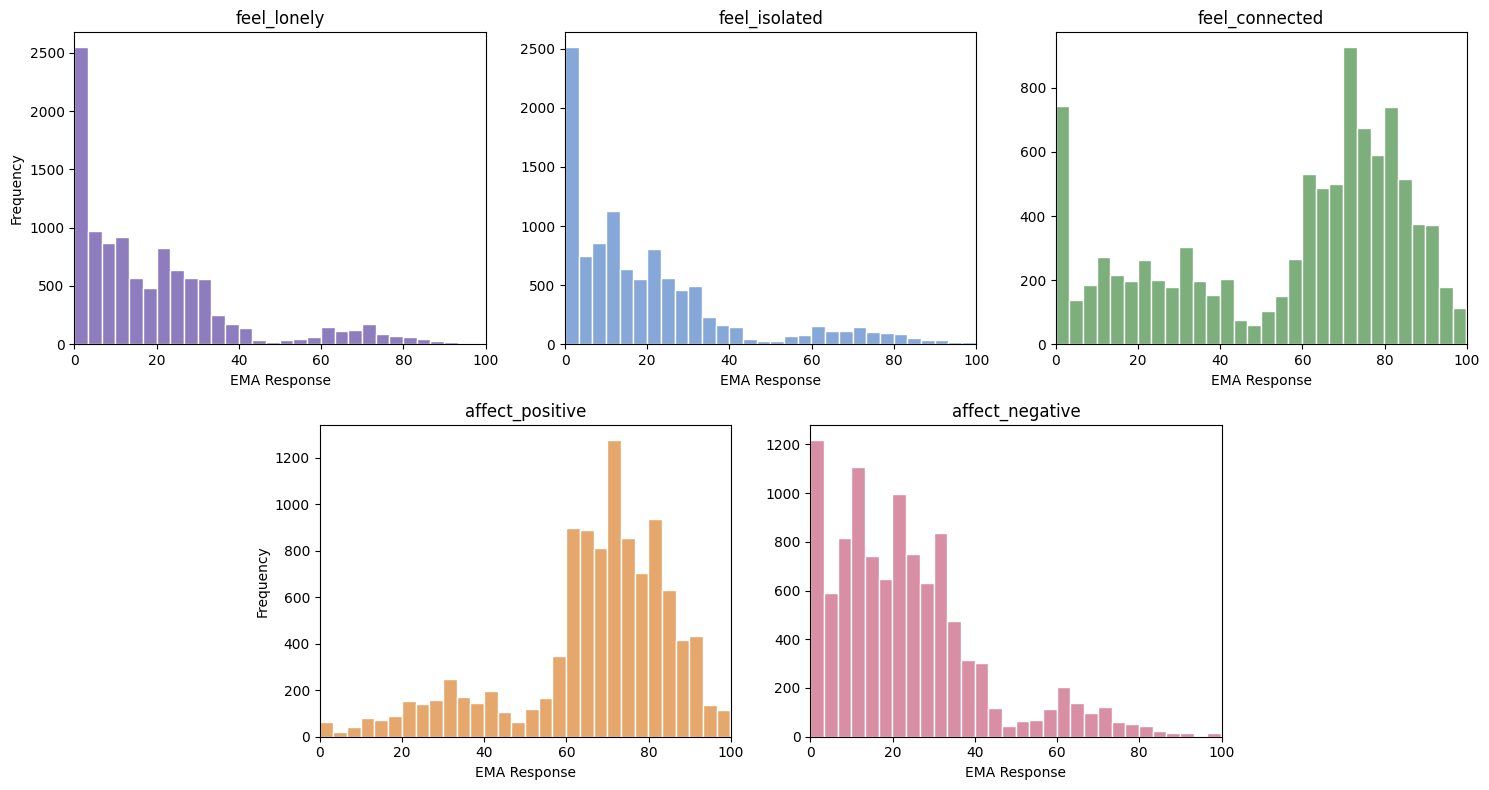

In [9]:
colors = ["#8E7DBE", "#86A8D9", "#7CAF7C", "#E5A76B", "#D88FA3"]

fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 6)

axes = [
    fig.add_subplot(gs[0, 0:2]),
    fig.add_subplot(gs[0, 2:4]),
    fig.add_subplot(gs[0, 4:6]),
    fig.add_subplot(gs[1, 1:3]),
    fig.add_subplot(gs[1, 3:5])
]

bins = np.arange(0, 105, 3.33)

for ax, label, color in zip(axes, LABELS, colors):
    ax.hist(ema_df[label].dropna(), bins=bins, color=color, edgecolor="white", linewidth=1)

    ax.set_title(label)
    ax.set_xlabel("EMA Response")
    ax.set_xlim(0, 100)
    ax.set_xticks(np.arange(0, 101, 20))
    ax.tick_params(axis="y", labelleft=True)

axes[0].set_ylabel("Frequency")
axes[3].set_ylabel("Frequency")

plt.tight_layout()
plt.show()